
NOTEBOOK 1: MIT-BIH PREPROCESSING PIPELINE

This notebook:
  1. Downloads / loads the MIT-BIH Arrhythmia Database from PhysioNet
  2. Applies bandpass filtering, R-peak segmentation, and edge-padding
  3. Constructs dual-lead + derivative (3-channel) segments
  4. Applies robust per-sample normalization
  5. Saves preprocessed arrays + metadata + split indices for:
     - Beat-wise (intra-patient) study
     - Record-wise (inter-patient) study
  6. Generates diagnostic visualizations (class distribution, sample beats,
     before/after filtering)

OUTPUTS (saved to ./preprocessed/):
  - X.npy                 : (N, 3, 375) preprocessed segments
  - y.npy                 : (N,) integer labels 0-4
  - record_ids.npy        : (N,) source record ID per beat
  - record_labels.json    : dict[record_id] -> list of labels in that record
  - beatwise_splits.json  : {"train_idx": [...], "val_idx": [...], "test_idx": [...]}
  - recordwise_folds.json: [{"train": [...], "val": [...], "test": [...]}, ...]




In [1]:
# Cell 1: Environment Setup
!pip install -q wfdb numpy scipy matplotlib seaborn pandas scikit-learn tqdm


import os
import json
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from scipy import signal as scipy_signal
from sklearn.model_selection import train_test_split, StratifiedKFold

import wfdb

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

SEED = 42
np.random.seed(SEED)
random_state = np.random.RandomState(SEED)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.5 MB/s eta 0:00:00


In [2]:

# CONFIGURATION

class Config:
    FS = 360.0               # MIT-BIH sampling frequency (Hz)
    WINDOW_SIZE = 375        # ~1.04 s window (PHM used 187; we use 375 with edge-padding)
    NUM_CLASSES = 5

    # Preprocessing
    BANDPASS_LOW = 0.5       # Hz: remove baseline wander
    BANDPASS_HIGH = 40.0     # Hz: remove muscle noise
    BANDPASS_ORDER = 4       # Butterworth
    USE_DERIVATIVE = True    # 3rd channel = first derivative of Lead 1

    # Normalization
    USE_ROBUST_NORM = True   # True = Median/IQR; False = min-max [-1,1]

    # Splits
    BEATWISE_TEST_FRAC = 0.20
    BEATWISE_VAL_FRAC = 0.125   # 10% of train carved out for early stopping
    RECORDWISE_N_SPLITS = 5

    # Output directory
    OUT_DIR = Path("./preprocessed")
    OUT_DIR.mkdir(exist_ok=True)

# AAMI class mapping
AAMI_MAP = {
    'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0,   # Normal
    'A': 1, 'a': 1, 'J': 1, 'S': 1,            # Supraventricular
    'V': 2, 'E': 2,                             # Ventricular
    'F': 3,                                     # Fusion
    '/': 4, 'f': 4, 'Q': 4                     # Unknown
}

CLASS_NAMES = {0: 'Normal (N)', 1: 'SVB (S)', 2: 'VEB (V)', 3: 'Fusion (F)', 4: 'Unknown (Q)'}

MITBIH_RECORDS = [
    100, 101, 102, 103, 104, 105, 106, 107, 108, 109,
    111, 112, 113, 114, 115, 116, 117, 118, 119, 121,
    122, 123, 124, 200, 201, 202, 203, 205, 207, 208,
    209, 210, 212, 213, 214, 215, 217, 219, 220, 221,
    222, 223, 228, 230, 231, 232, 233, 234
]

print(f"[Config] Window size: {Config.WINDOW_SIZE} samples ({Config.WINDOW_SIZE/Config.FS:.3f} s)")
print(f"[Config] Output dir: {Config.OUT_DIR.resolve()}")



[Config] Window size: 375 samples (1.042 s)
[Config] Output dir: /kaggle/working/preprocessed


In [3]:

# Cell 2: Signal Loading & Filtering

def load_record(record_id):
    """Load WFDB record and annotation from PhysioNet."""
    record = wfdb.rdrecord(str(record_id), pn_dir='mitdb')
    ann = wfdb.rdann(str(record_id), 'atr', pn_dir='mitdb')
    return record, ann


def bandpass_filter(sig, lowcut=Config.BANDPASS_LOW, highcut=Config.BANDPASS_HIGH,
                    fs=Config.FS, order=Config.BANDPASS_ORDER):
    """Zero-phase Butterworth bandpass (filtfilt)."""
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = scipy_signal.butter(order, [low, high], btype='band')
    return scipy_signal.filtfilt(b, a, sig)



In [4]:

# Cell 3: Beat Extraction with Edge-Padding

def extract_beats_from_record(record_id, window=Config.WINDOW_SIZE):
    """
    Extract all valid beat segments from a single record.
    Uses EDGE-PADDING for beats near recording boundaries (no beats dropped).
    Returns list of (segment_array, aami_label) tuples.
    Segment shape: (3, window) -> [Lead1, Lead2, Derivative].
    """
    try:
        record, ann = load_record(record_id)
    except Exception as e:
        print(f"[WARN] Error loading record {record_id}: {e}")
        return []

    signals = record.p_signal
    if signals is None or signals.size == 0:
        return []

    n_leads = signals.shape[1]
    half_window = window // 2
    segments = []

    # Filter each lead independently BEFORE segmentation
    filtered = np.zeros_like(signals)
    for lead in range(n_leads):
        filtered[:, lead] = bandpass_filter(signals[:, lead])

    lead1_idx = 0
    lead2_idx = 1 if n_leads > 1 else 0

    for i, sample_idx in enumerate(ann.sample):
        symbol = ann.symbol[i]
        if symbol not in AAMI_MAP:
            continue

        start = sample_idx - half_window
        end = start + window

        # ---- EDGE PADDING FIX: recover boundary beats ----
        if start < 0:
            pad_left = abs(start)
            seg_raw = np.pad(filtered[:end], ((pad_left, 0), (0, 0)), mode='edge')
        elif end > len(filtered):
            pad_right = end - len(filtered)
            seg_raw = np.pad(filtered[start:], ((0, pad_right), (0, 0)), mode='edge')
        else:
            seg_raw = filtered[start:end]
        # --------------------------------------------------

        lead1 = seg_raw[:, lead1_idx]
        lead2 = seg_raw[:, lead2_idx]
        seg = np.stack([lead1, lead2], axis=0)  # (2, window)

        if Config.USE_DERIVATIVE:
            deriv = np.gradient(lead1)
            deriv = np.expand_dims(deriv, axis=0)  # (1, window)
            seg = np.concatenate([seg, deriv], axis=0)  # (3, window)

        segments.append((seg, AAMI_MAP[symbol]))

    return segments



In [5]:

# Cell 4: Normalization

def robust_normalize(segment):
    """Robust normalization: median + IQR (robust to artifact spikes)."""
    median = np.median(segment, axis=1, keepdims=True)
    q75 = np.percentile(segment, 75, axis=1, keepdims=True)
    q25 = np.percentile(segment, 25, axis=1, keepdims=True)
    iqr = q75 - q25
    iqr = np.where(iqr == 0, 1.0, iqr)
    return (segment - median) / iqr


def minmax_normalize(segment):
    """PHM-style normalization to [-1, 1]."""
    min_val = segment.min(axis=1, keepdims=True)
    max_val = segment.max(axis=1, keepdims=True)
    denom = max_val - min_val
    denom = np.where(denom == 0, 1.0, denom)
    return 2 * (segment - min_val) / denom - 1.0



In [6]:
# Cell 5: Main Extraction Loop

print("\n[1/5] Extracting beats from all 48 records...")
all_segments = []
all_labels = []
all_record_ids = []
record_labels_map = {}   # record_id -> list of labels

for rec_id in tqdm(MITBIH_RECORDS, desc="Extracting"):
    segs = extract_beats_from_record(rec_id)
    if segs:
        segments, labels = zip(*segs)
        segments = [s for s in segments]
        labels = list(labels)
        all_segments.extend(segments)
        all_labels.extend(labels)
        all_record_ids.extend([rec_id] * len(labels))
        record_labels_map[int(rec_id)] = labels
    else:
        record_labels_map[int(rec_id)] = []

print(f"[INFO] Total beats extracted: {len(all_labels)}")
print(f"[INFO] Class distribution: {dict(Counter(all_labels))}")

# Normalize all segments
print("\n[2/5] Normalizing segments...")
if Config.USE_ROBUST_NORM:
    all_segments = [robust_normalize(seg) for seg in tqdm(all_segments, desc="Normalizing")]
else:
    all_segments = [minmax_normalize(seg) for seg in tqdm(all_segments, desc="Normalizing")]

X = np.stack(all_segments, axis=0).astype(np.float32)   # (N, 3, 375)
y = np.array(all_labels, dtype=np.int64)
record_ids_arr = np.array(all_record_ids, dtype=np.int32)

print(f"[INFO] X shape: {X.shape}, dtype: {X.dtype}")
print(f"[INFO] y shape: {y.shape}, dtype: {y.dtype}")




[1/5] Extracting beats from all 48 records...


Extracting:   0%|          | 0/48 [00:00<?, ?it/s]

[INFO] Total beats extracted: 109494
[INFO] Class distribution: {0: 90631, 1: 2781, 2: 7236, 4: 8043, 3: 803}

[2/5] Normalizing segments...


Normalizing:   0%|          | 0/109494 [00:00<?, ?it/s]

[INFO] X shape: (109494, 3, 375), dtype: float32
[INFO] y shape: (109494,), dtype: int64


In [7]:

# Cell 6: Save Raw Arrays

print("\n[3/5] Saving preprocessed arrays...")
np.save(Config.OUT_DIR / "X.npy", X)
np.save(Config.OUT_DIR / "y.npy", y)
np.save(Config.OUT_DIR / "record_ids.npy", record_ids_arr)

with open(Config.OUT_DIR / "record_labels.json", "w") as f:
    json.dump(record_labels_map, f)

print(f"[OK] Saved to {Config.OUT_DIR}")




[3/5] Saving preprocessed arrays...
[OK] Saved to preprocessed


In [8]:

# Cell 7: Beat-Wise Split Indices (Intra-Patient)

print("\n[4/5] Generating beat-wise stratified splits...")

# 80/20 stratified split -> then 10% val from train
idx = np.arange(len(y))
idx_train, idx_test = train_test_split(
    idx, test_size=Config.BEATWISE_TEST_FRAC, random_state=SEED, stratify=y
)
idx_train, idx_val = train_test_split(
    idx_train, test_size=Config.BEATWISE_VAL_FRAC, random_state=SEED, stratify=y[idx_train]
)

beatwise_splits = {
    "train_idx": idx_train.tolist(),
    "val_idx": idx_val.tolist(),
    "test_idx": idx_test.tolist()
}
with open(Config.OUT_DIR / "beatwise_splits.json", "w") as f:
    json.dump(beatwise_splits, f)

print(f"[Beat-Wise] Train: {len(idx_train)}, Val: {len(idx_val)}, Test: {len(idx_test)}")
print(f"[Beat-Wise] Test class dist: {dict(Counter(y[idx_test]))}")



[4/5] Generating beat-wise stratified splits...
[Beat-Wise] Train: 76645, Val: 10950, Test: 21899
[Beat-Wise] Test class dist: {np.int64(0): 18126, np.int64(3): 161, np.int64(2): 1447, np.int64(4): 1609, np.int64(1): 556}


In [9]:

# Cell 8: Record-Wise Stratified Fold Indices (Inter-Patient)

print("\n[5/5] Generating record-wise stratified folds...")

def get_record_stratification(record_ids, rec_labels_dict):
    """4-level stratification: 0=common only, 1=has S, 2=has F, 3=has both."""
    strata = []
    for rec_id in record_ids:
        labels = set(rec_labels_dict.get(int(rec_id), []))
        has_S = 1 in labels
        has_F = 3 in labels
        if has_S and has_F:
            strata.append(3)
        elif has_F:
            strata.append(2)
        elif has_S:
            strata.append(1)
        else:
            strata.append(0)
    return np.array(strata)

record_strata = get_record_stratification(MITBIH_RECORDS, record_labels_map)

skf = StratifiedKFold(n_splits=Config.RECORDWISE_N_SPLITS, shuffle=True, random_state=SEED)
recordwise_folds = []

for fold_idx, (train_idx, test_idx) in enumerate(skf.split(MITBIH_RECORDS, record_strata)):
    train_recs = [int(MITBIH_RECORDS[i]) for i in train_idx]
    test_recs = [int(MITBIH_RECORDS[i]) for i in test_idx]

    # Class-aware validation selection (guarantee minority coverage)
    has_S = [r for r in train_recs if 1 in set(record_labels_map.get(r, []))]
    has_F = [r for r in train_recs if 3 in set(record_labels_map.get(r, []))]
    val_recs = set()
    if has_S:
        val_recs.add(has_S[-1])
    if has_F:
        val_recs.add(has_F[-1])
    target_n = max(len(val_recs), int(0.15 * len(train_recs)))
    remaining = [r for r in train_recs if r not in val_recs]
    random_state.shuffle(remaining)
    val_recs.update(remaining[:target_n - len(val_recs)])
    val_recs = list(val_recs)
    train_recs_final = [r for r in train_recs if r not in val_recs]

    recordwise_folds.append({
        "fold": fold_idx,
        "train": train_recs_final,
        "val": val_recs,
        "test": test_recs
    })

    print(f"  Fold {fold_idx+1}: Train={len(train_recs_final)} recs, Val={len(val_recs)} recs, Test={len(test_recs)} recs")

with open(Config.OUT_DIR / "recordwise_folds.json", "w") as f:
    json.dump(recordwise_folds, f)

print(" All splits saved.")



[5/5] Generating record-wise stratified folds...
  Fold 1: Train=33 recs, Val=5 recs, Test=10 recs
  Fold 2: Train=33 recs, Val=5 recs, Test=10 recs
  Fold 3: Train=33 recs, Val=5 recs, Test=10 recs
  Fold 4: Train=34 recs, Val=5 recs, Test=9 recs
  Fold 5: Train=34 recs, Val=5 recs, Test=9 recs
 All splits saved.



[6/6] Generating diagnostic plots...


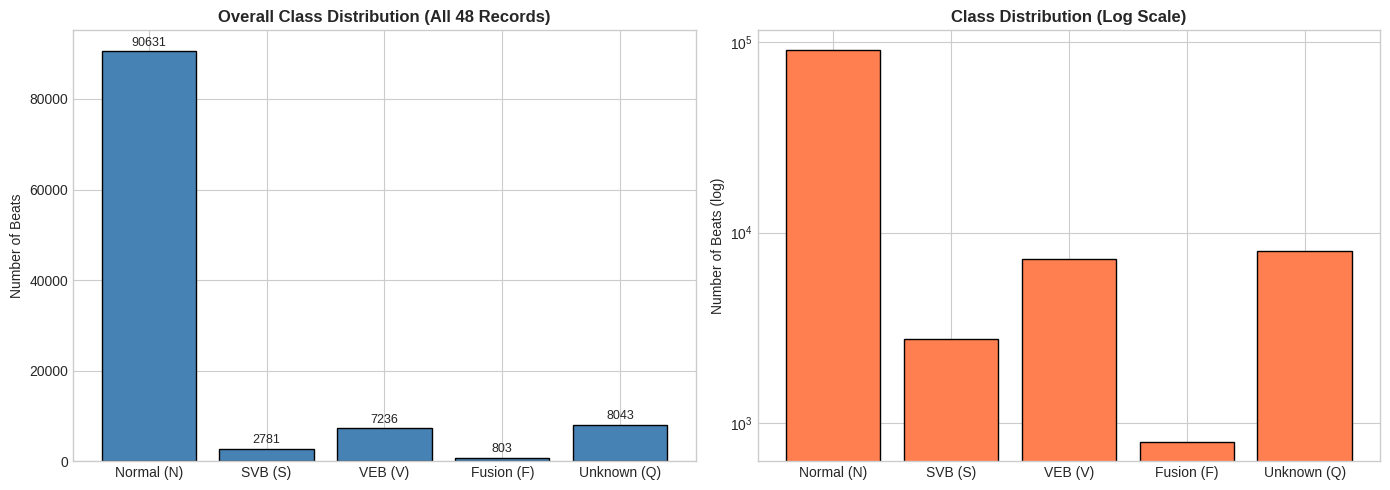

In [10]:
# ==============================================================================
# Cell 9: Diagnostic Visualizations
# ==============================================================================
print("\n[6/6] Generating diagnostic plots...")

# --- Plot 1: Class Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
counts = pd.Series(y).value_counts().sort_index()
axes[0].bar([CLASS_NAMES[i] for i in counts.index], counts.values, color='steelblue', edgecolor='black')
axes[0].set_title("Overall Class Distribution (All 48 Records)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Number of Beats")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 500, str(v), ha='center', va='bottom', fontsize=9)

# Log scale for clarity
axes[1].bar([CLASS_NAMES[i] for i in counts.index], counts.values, color='coral', edgecolor='black')
axes[1].set_yscale('log')
axes[1].set_title("Class Distribution (Log Scale)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Number of Beats (log)")
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "01_class_distribution.png", dpi=300, bbox_inches='tight')
plt.show()


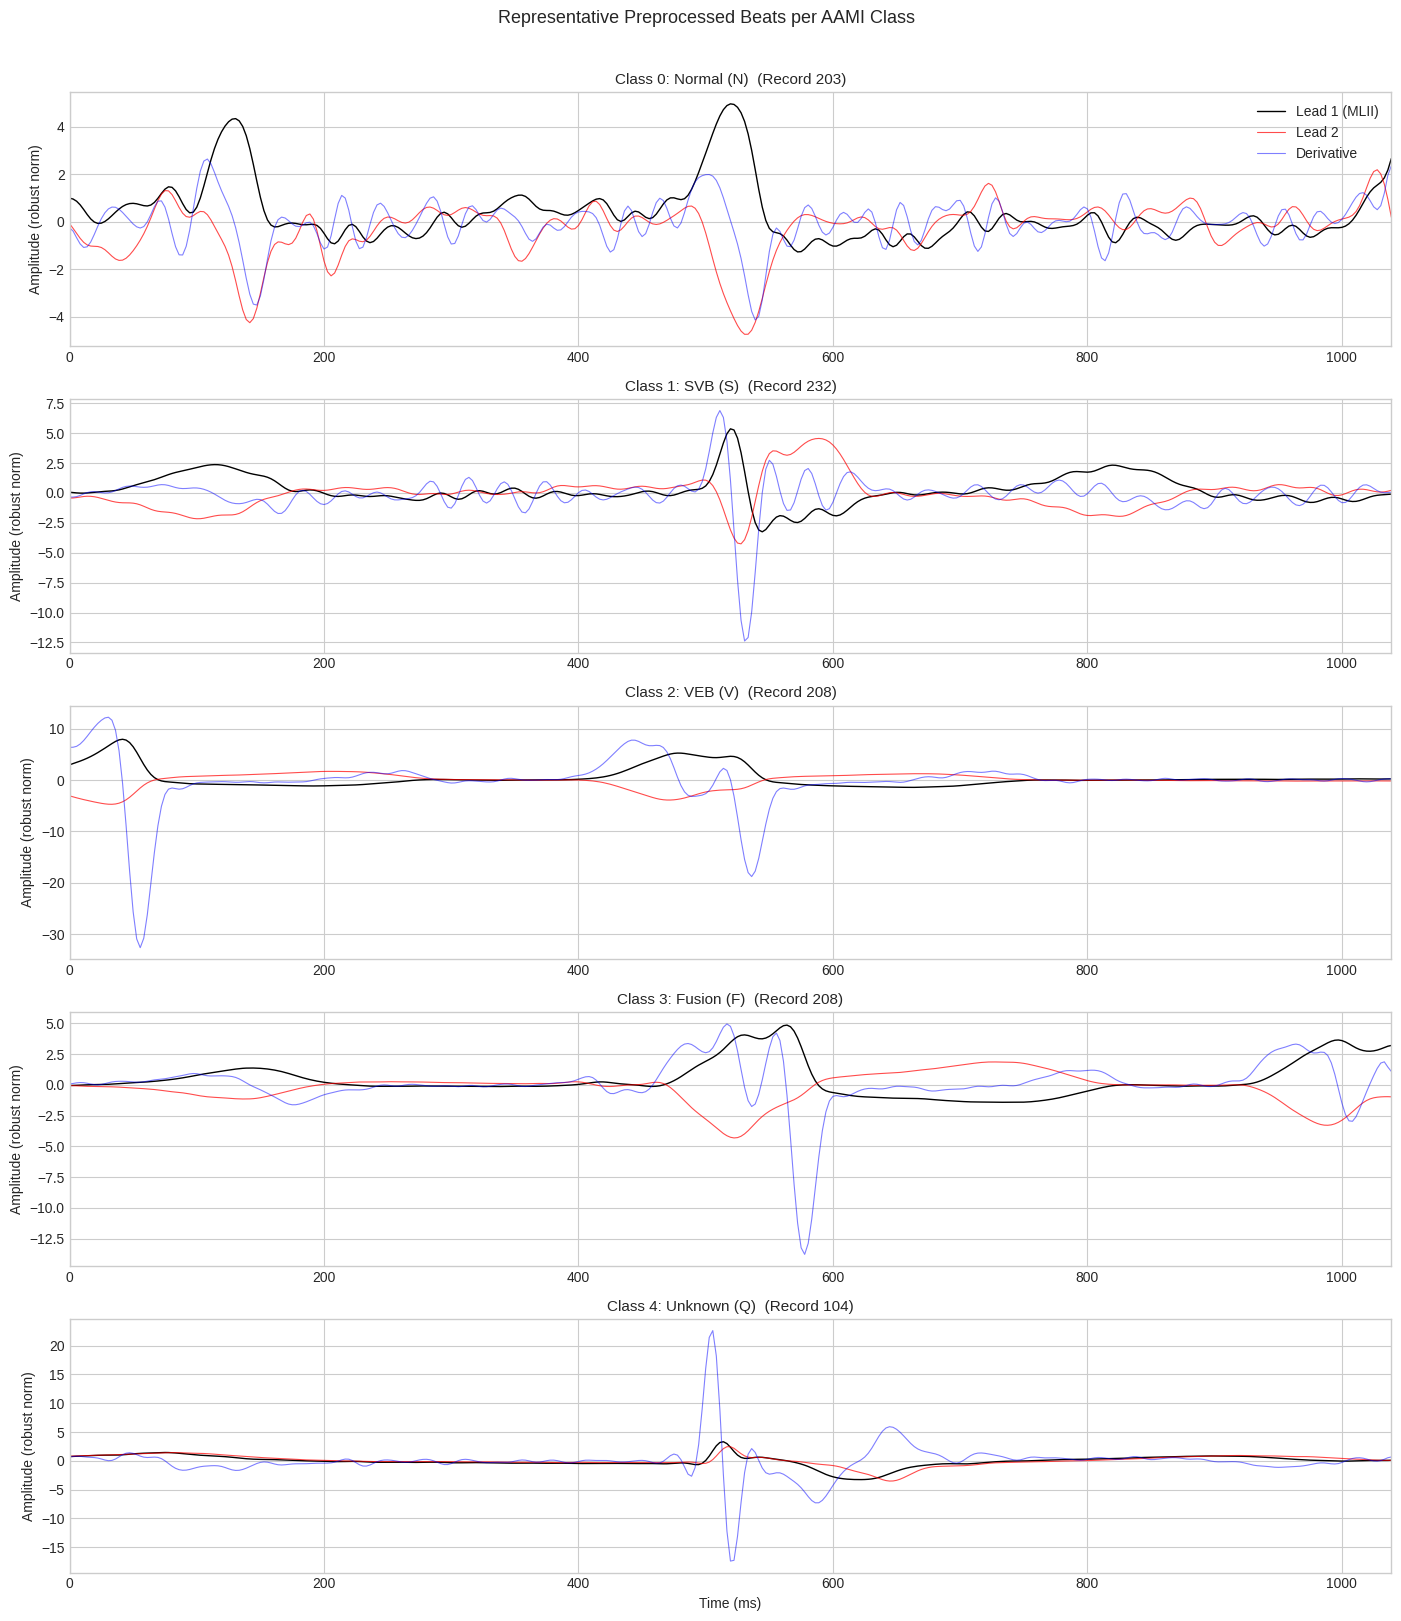

In [11]:
# --- Plot 2: Sample Beats per Class ---
fig, axes = plt.subplots(5, 1, figsize=(14, 16))
time_axis = np.arange(Config.WINDOW_SIZE) / Config.FS * 1000  # ms

for cls in range(5):
    idx_cls = np.where(y == cls)[0]
    if len(idx_cls) == 0:
        continue
    # Pick a median-length sample (avoid outliers)
    sample_idx = idx_cls[len(idx_cls) // 2]
    seg = X[sample_idx]

    ax = axes[cls]
    ax.plot(time_axis, seg[0], 'k', linewidth=1.0, label='Lead 1 (MLII)')
    ax.plot(time_axis, seg[1], 'r', linewidth=0.8, alpha=0.7, label='Lead 2')
    ax.plot(time_axis, seg[2], 'b', linewidth=0.8, alpha=0.5, label='Derivative')
    ax.set_title(f"Class {cls}: {CLASS_NAMES[cls]}  (Record {record_ids_arr[sample_idx]})", fontsize=11)
    ax.set_ylabel("Amplitude (robust norm)")
    ax.set_xlim([0, time_axis[-1]])
    if cls == 0:
        ax.legend(loc='upper right')

axes[-1].set_xlabel("Time (ms)")
plt.suptitle("Representative Preprocessed Beats per AAMI Class", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "02_sample_beats_per_class.png", dpi=300, bbox_inches='tight')
plt.show()


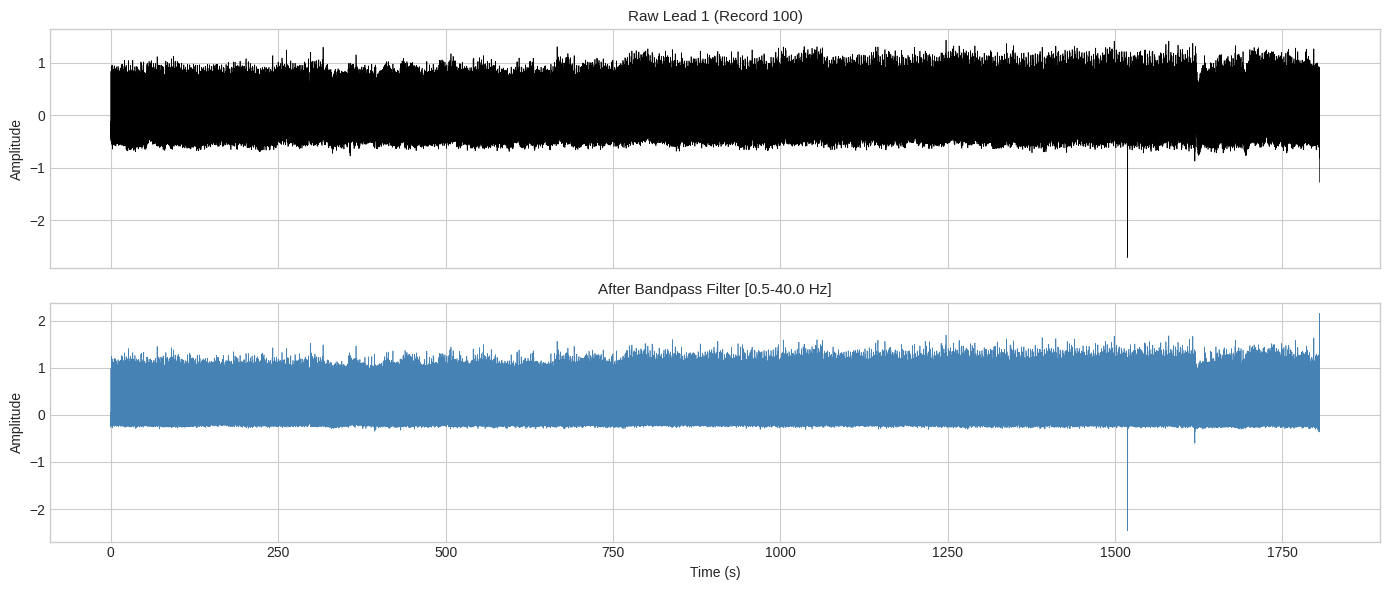

In [12]:
# --- Plot 3: Before/After Filter Example (Record 100) ---
rec, ann = load_record(100)
sig_raw = rec.p_signal[:, 0]
sig_filt = bandpass_filter(sig_raw)

t = np.arange(len(sig_raw)) / Config.FS
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(t, sig_raw, 'k', linewidth=0.5)
axes[0].set_title("Raw Lead 1 (Record 100)", fontsize=11)
axes[0].set_ylabel("Amplitude")
axes[1].plot(t, sig_filt, 'steelblue', linewidth=0.5)
axes[1].set_title(f"After Bandpass Filter [{Config.BANDPASS_LOW}-{Config.BANDPASS_HIGH} Hz]", fontsize=11)
axes[1].set_ylabel("Amplitude")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "03_filter_before_after.png", dpi=300, bbox_inches='tight')
plt.show()


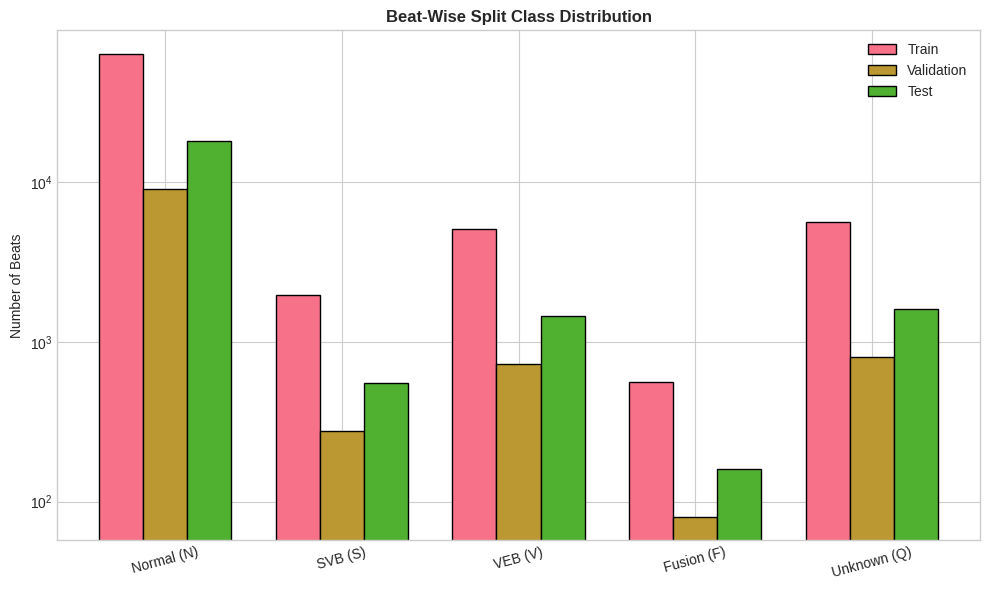

In [13]:
# --- Plot 4: Train/Val/Test Distribution (Beat-Wise) ---
fig, ax = plt.subplots(figsize=(10, 6))
split_names = ['Train', 'Validation', 'Test']
split_indices = [idx_train, idx_val, idx_test]
x_pos = np.arange(Config.NUM_CLASSES)
width = 0.25

for i, (name, indices) in enumerate(zip(split_names, split_indices)):
    dist = pd.Series(y[indices]).value_counts().sort_index().values
    ax.bar(x_pos + i * width, dist, width, label=name, edgecolor='black')

ax.set_xticks(x_pos + width)
ax.set_xticklabels([CLASS_NAMES[i] for i in range(Config.NUM_CLASSES)], rotation=15)
ax.set_ylabel("Number of Beats")
ax.set_title("Beat-Wise Split Class Distribution", fontsize=12, fontweight='bold')
ax.legend()
ax.set_yscale('log')
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "04_beatwise_split_distribution.png", dpi=300, bbox_inches='tight')
plt.show()


In [14]:
print("\n" + "="*70)
print("PREPROCESSING COMPLETED")
print("="*70)
print(f"Output directory: {Config.OUT_DIR.resolve()}")
print(f"Total beats: {len(y)}")
print(f"Files generated: X.npy, y.npy, record_ids.npy, record_labels.json,")
print(f"                 beatwise_splits.json, recordwise_folds.json")
print(f"Diagnostic plots: 01_class_distribution.png, 02_sample_beats_per_class.png,")
print(f"                  03_filter_before_after.png, 04_beatwise_split_distribution.png")
print("="*70)


PREPROCESSING COMPLETED
Output directory: /kaggle/working/preprocessed
Total beats: 109494
Files generated: X.npy, y.npy, record_ids.npy, record_labels.json,
                 beatwise_splits.json, recordwise_folds.json
Diagnostic plots: 01_class_distribution.png, 02_sample_beats_per_class.png,
                  03_filter_before_after.png, 04_beatwise_split_distribution.png
